Summarize the recorded external multiple-choice benchmark experiments.


In [1]:
import os, sys, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def _build_data_tools():
    import json
    import os
    import re
    import unicodedata
    import warnings
    import numpy as np
    import pandas as pd
    from scipy import stats
    warnings.filterwarnings('ignore')

    def path_join(*parts):
        return os.path.normpath(os.path.join(*parts))

    def normalize_newlines(frame):
        for column in frame.select_dtypes(include=['object', 'string']).columns:
            frame[column] = frame[column].map(lambda value: value.replace('\r\n', '\n').replace('\r', '\n') if isinstance(value, str) else value)
        return frame
    from pathlib import Path
    _start = Path.cwd().resolve()
    _repo = next((p for p in (_start, *_start.parents) if (p / 'experiments/clinical_protocols').is_dir() and (p / 'data').is_dir()), None)
    if _repo is None:
        raise FileNotFoundError('Run the notebook from inside the repository.')
    if os.name == 'nt' and (not str(_repo).startswith(chr(92) * 2 + '?' + chr(92))):
        _repo = Path(chr(92) * 2 + '?' + chr(92) + str(_repo))
    GOLD = str(_repo)
    PAPER = str(_repo / 'results/clinical_evaluation')
    HERE = str(_repo / 'analyses/clinical_evaluation')
    ALPHA = GOLD
    RESEARCH = GOLD
    TABLES = path_join(PAPER, 'tables')
    FIGURES = path_join(PAPER, 'figures')
    os.makedirs(TABLES, exist_ok=True)
    os.makedirs(FIGURES, exist_ok=True)
    DATASET = str(_repo / 'data' / 'limfmed_dataset_gold.csv')
    PBASE = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_complete'
    PBASE_NON = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_truncated'
    ORG_DS = 'experiments/clinical_protocols/delphi_panels/heterogeneous_deepseek_organizer_complete'
    ORG_QWEN = 'experiments/clinical_protocols/delphi_panels/heterogeneous_qwen_organizer_complete'
    ORG_GEM = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gemini_external_organizer'
    PWEAK = 'experiments/clinical_protocols/delphi_panels/panel_qwen_organizer_gemini_deepseek_pro'
    PMIXED = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_gemini_glm'
    PSTRONG = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_glm_gpt120'
    HOMOG = {'gpt': 'experiments/homogeneous_panels/three_gpt_members', 'qwen': 'experiments/homogeneous_panels/three_qwen_members', 'deepseekv4': 'experiments/homogeneous_panels/three_deepseekv4_members_complete', 'gemini': 'experiments/homogeneous_panels/three_gemini_members'}
    FIX_PBASE = 'experiments/fixed_length_controls/delphi_panels/internal_panel_variants/standard_protocol/heterogeneous_gpt120_organizer'
    SINGLES = ['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
    MODEL_NAME = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b-a22b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi'}
    PANELS = {'P-base': (PBASE, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gpt', True), 'P-base/org-ds': (ORG_DS, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'deepseekv4', True), 'P-base/org-qwen': (ORG_QWEN, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'qwen', True), 'P-base/org-gemini': (ORG_GEM, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gemini', False), 'P-weak': (PWEAK, 'delphi_pweak_{d}_judge.csv', ['qwen', 'gemini', 'deepseekv4pro'], 'qwen', True), 'P-mixed': (PMIXED, 'delphi_pmixed_{d}_judge.csv', ['deepseekv4', 'gemini', 'glm'], 'deepseekv4', True), 'P-strong': (PSTRONG, 'delphi_pstrong_{d}_judge.csv', ['deepseekv4', 'glm', 'gpt'], 'deepseekv4', True), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_{d}_judge.csv', ['gpt'] * 3, 'gpt', True), 'homog qwen': (HOMOG['qwen'], 'delphi_homog_qwen_{d}_judge.csv', ['qwen'] * 3, 'qwen', True), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_{d}_judge.csv', ['deepseekv4'] * 3, 'deepseekv4', True), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_{d}_judge.csv', ['gemini'] * 3, 'gemini', True)}
    HETERO = ['P-base', 'P-weak', 'P-mixed', 'P-strong']
    HOMOGS = ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
    ORGANIZER_ARMS = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
    RAW_RUN = {'P-base': PBASE + '/delphi_noroles.csv', 'P-base/org-ds': ORG_DS + '/delphi_noroles.csv', 'P-base/org-qwen': ORG_QWEN + '/delphi_noroles.csv', 'P-base/org-gemini': ORG_GEM + '/delphi_noroles.csv', 'P-weak': PWEAK + '/delphi_pweak_noroles.csv', 'P-mixed': PMIXED + '/delphi_pmixed_noroles.csv', 'P-strong': PSTRONG + '/delphi_pstrong_noroles.csv', 'homog gpt': HOMOG['gpt'] + '/delphi_homog_gpt_noroles.csv', 'homog qwen': HOMOG['qwen'] + '/delphi_homog_qwen_noroles.csv', 'homog deepseekv4': HOMOG['deepseekv4'] + '/delphi_homog_deepseekv4_noroles.csv', 'homog gemini': HOMOG['gemini'] + '/delphi_homog_gemini_noroles.csv'}
    ROUNDS_EVAL = {'P-base': (PBASE, 'delphi_base_noroles_protocol_r{r}_judge.csv'), 'P-weak': (PWEAK, 'delphi_pweak_noroles_protocol_r{r}_judge.csv'), 'P-mixed': (PMIXED, 'delphi_pmixed_noroles_protocol_r{r}_judge.csv'), 'P-strong': (PSTRONG, 'delphi_pstrong_noroles_protocol_r{r}_judge.csv'), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_noroles_protocol_r{r}_judge.csv'), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_noroles_protocol_r{r}_judge.csv'), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_noroles_protocol_r{r}_judge.csv')}

    def baseline_path(model, design='noroles', variant='nofix'):
        return f"experiments/{('clinical_protocols' if variant == 'nofix' else 'fixed_length_controls')}/single_model_baselines/baseline_{model}/llm_as_judge/baseline_{design}_{model}_judge.csv"

    def panel_path(name, design='noroles'):
        d, f, *_ = PANELS[name]
        return d + '/llm_as_judge/' + f.format(d=design)

    def _abs(rel):
        return rel if os.path.isabs(rel) else path_join(GOLD, rel)

    def read_csv(rel, filter_result=True):
        p = _abs(rel)
        if not os.path.exists(p):
            return None
        d = normalize_newlines(pd.read_csv(p, sep=';', encoding='utf-8-sig', low_memory=False))
        d.columns = [c.lstrip('\ufeff') for c in d.columns]
        if filter_result and 'table_source' in d.columns:
            d = d[d['table_source'].fillna('result_df') == 'result_df']
        return d

    def read_judge(rel):
        d = read_csv(rel)
        if d is None or 'Judge_score' not in d.columns:
            return None
        d = d.dropna(subset=['Judge_score', 'Vignette']).drop_duplicates('Vignette', keep='first')
        d['Judge_score'] = pd.to_numeric(d['Judge_score'], errors='coerce')
        return d.set_index('Vignette')

    def load_main_arms(design='noroles', include_usc=False):
        arms = {}
        for m in SINGLES:
            d = read_judge(baseline_path(m, design))
            if d is not None:
                arms[m] = d
        for name in PANELS:
            d = read_judge(panel_path(name, design))
            if d is not None:
                arms[name] = d
        if include_usc and design == 'noroles':
            for k in (3, 5, 7):
                d = read_judge(f'experiments/token_budget_controls/universal_self_consistency_gpt_seven_samples/llm_as_judge/usc_gpt_sc{k}_judge.csv')
                if d is not None:
                    arms[f'USC@{k} gpt'] = d
        return arms

    def score(arms, name):
        return arms[name]['Judge_score'].astype(float)

    def dataset():
        d = normalize_newlines(pd.read_csv(DATASET, sep=None, engine='python'))
        return d

    def protocol_text(d):
        for c in ('winner_protocol', 'baseline_protocol_anonymous', 'baseline_protocol'):
            if c in d.columns:
                return d[c].astype(str)
        raise KeyError('no protocol column')

    def strip_author(text):
        if not isinstance(text, str):
            return ''
        return re.split('(?im)^\\s*Protocol Author\\s*:', text, maxsplit=1)[0].rstrip()

    def n_words(text):
        return len(re.findall('\\S+', strip_author(text))) if isinstance(text, str) else np.nan

    def items(d):
        rows = []
        for v, s in d['judge_details'].dropna().items():
            try:
                arr = json.loads(s)
            except Exception:
                continue
            for it in arr:
                ax = next((t.split(':', 1)[1] for t in it.get('tags') or [] if isinstance(t, str) and t.startswith('axis:')), None)
                rows.append((v, int(it['id']), int(it.get('points', 0) or 0), ax, bool(it.get('met'))))
        return pd.DataFrame(rows, columns=['Vignette', 'cid', 'points', 'axis', 'met'])

    def item_matrix(arms, names, positive_only=True):
        frames = []
        for n in names:
            it = items(arms[n]).set_index(['Vignette', 'cid'])
            frames.append(it['met'].astype(int).rename(n))
            meta = it[['points', 'axis']]
        m = pd.concat(frames, axis=1, join='inner')
        m = m.join(meta, how='left')
        if positive_only:
            m = m[m['points'] > 0]
        return m
    ORD = {'SELF': 0, 'NONEMERG': 1, 'EMERG': 2}
    GT = {'Self-care appropriate': 'SELF', 'Requires non-emergent care': 'NONEMERG', 'Requires emergent care': 'EMERG'}
    _DASH = dict.fromkeys(map(ord, '‐‑‒–—―−\xad'), '-')

    def norm_label(x):
        if not isinstance(x, str) or not x.strip():
            return None
        x = x.strip()
        if x in GT:
            return GT[x]
        s = unicodedata.normalize('NFKC', x).translate(_DASH).lower()
        s = re.sub('\\s+', ' ', re.sub('[^a-z\\- ]', ' ', s)).strip()
        for k, v in (('requires emergent care', 'EMERG'), ('requires non-emergent care', 'NONEMERG'), ('self-care appropriate', 'SELF')):
            if k in s:
                return v
        if 'non-emergent' in s or 'non emergent' in s:
            return 'NONEMERG'
        if 'emergent' in s or 'emergency' in s:
            return 'EMERG'
        if 'self' in s:
            return 'SELF'
        return None
    _PAT = re.compile('emergency\\s*type\\s*[:\\-]\\s*[\\*_`#\\s]*([^\\n\\r\\*_|]{0,90})', re.I)

    def parse_triage(text):
        if not isinstance(text, str) or not text.strip():
            return None
        m = _PAT.search(unicodedata.normalize('NFKC', text).translate(_DASH))
        return norm_label(m.group(1)) if m else None

    def predicted_triage(d):
        if 'delphi_consensus_emergency_type' in d.columns:
            s = d['delphi_consensus_emergency_type'].map(norm_label)
            if s.notna().mean() > 0.5:
                return s
        return protocol_text(d).map(parse_triage)

    def true_triage(d):
        return d['Type'].map(GT)

    def participants(d):
        return sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_emergency__')))

    def paired(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(float), b.loc[ix].astype(float))
        dd = x - y
        p = stats.wilcoxon(x, y).pvalue if (dd != 0).any() else np.nan
        return {'n': len(ix), 'delta': float(dd.mean()), 'share_gt': float((dd > 0).mean()), 'p_wilcoxon': float(p)}

    def boot_ci(x, B=10000, seed=20260922, alpha=0.05, stat=np.mean):
        rng = np.random.default_rng(seed)
        x = np.asarray(x, float)
        n = len(x)
        idx = rng.integers(0, n, (B, n))
        s = stat(x[idx], axis=1)
        return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))

    def boot_ci_two_level(x, cluster, B=10000, seed=20260922, alpha=0.05):
        rng = np.random.default_rng(seed)
        df = pd.DataFrame({'x': np.asarray(x, float), 'c': np.asarray(cluster)})
        groups = [g['x'].to_numpy() for _, g in df.groupby('c')]
        G = len(groups)
        out = np.empty(B)
        for b in range(B):
            pick = rng.integers(0, G, G)
            vals = []
            for i in pick:
                g = groups[i]
                vals.append(g[rng.integers(0, len(g), len(g))])
            out[b] = np.concatenate(vals).mean()
        return (float(np.quantile(out, alpha / 2)), float(np.quantile(out, 1 - alpha / 2)))

    def holm(p):
        p = np.asarray(p, float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for i, k in enumerate(order):
            run = max(run, (m - i) * p[k])
            adj[k] = min(run, 1.0)
        return adj

    def mcnemar_exact(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(bool), b.loc[ix].astype(bool))
        n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
        p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        return {'n': len(ix), 'acc_a': float(x.mean()), 'acc_b': float(y.mean()), 'n10': n10, 'n01': n01, 'p': float(p)}

    def wilson(k, n, z=1.96):
        p = k / n
        d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
        return (c - h, c + h)

    def tost_paired(dvec, margin):
        d = np.asarray(dvec, float)
        n = len(d)
        m, se = (d.mean(), d.std(ddof=1) / np.sqrt(n))
        p_low = stats.t.sf((m + margin) / se, n - 1)
        p_up = stats.t.cdf((m - margin) / se, n - 1)
        return float(max(p_low, p_up))

    def fmt_p(p):
        if p is None or not np.isfinite(p):
            return 'n/a'
        if p < 0.0001:
            return f'{p:.1e}'
        return f'{p:.3f}' if p >= 0.001 else f'{p:.4f}'

    def save_table(df, name, index=True):
        path = path_join(TABLES, name)
        df.to_csv(path, sep=';', encoding='utf-8-sig', index=index)
        print(f'saved tables/{name} ({len(df)} rows)')
        return path
    return locals()
from types import SimpleNamespace
P = SimpleNamespace(**_build_data_tools())
del _build_data_tools
pd.set_option('display.width', 220)
E = 'experiments'
SYS = {'gpt-oss-120b': (E + '/external_benchmarks/medmcqa/baseline_gpt/baseline_medmcqa_gpt.csv', 'baseline_selected_option', 'single'), 'qwen3-235b': (E + '/external_benchmarks/medmcqa/baseline_qwen/baseline_medmcqa_qwen.csv', 'baseline_selected_option', 'single'), 'deepseek-v4-flash': (E + '/external_benchmarks/medmcqa/baseline_deepseekv4/baseline_medmcqa_deepseekv4.csv', 'baseline_selected_option', 'single'), 'qwen3.6-35b': (E + '/external_benchmarks/initial_runs/baseline_qwen36/baseline_medmcqa_qwen36.csv', 'baseline_selected_option', 'single'), 'aliceai-llm': (E + '/external_benchmarks/initial_runs/baseline_alice/baseline_medmcqa_alice.csv', 'baseline_selected_option', 'single'), 'Optimum (gpt·qwen3-235b·qwen3.6)': (E + '/external_benchmarks/initial_runs/heterogeneous_gpt120_organizer/delphi_medmcqa_noroles.csv', 'delphi_consensus_selected_option', 'panel'), 'AC-Alice (gpt·qwen3-235b·alice)': (E + '/external_benchmarks/initial_runs/panel_gpt120_organizer_qwen_alice/delphi_medmcqa_noroles.csv', 'delphi_consensus_selected_option', 'panel'), 'AC-DeepSeek (gpt·qwen3-235b·deepseek-v4)': (E + '/external_benchmarks/medmcqa/panel_gpt120_organizer_qwen_deepseek/delphi_medmcqa_noroles.csv', 'delphi_consensus_selected_option', 'panel'), 'DeepSeek trio (deepseek-v4 ×3)': (E + '/external_benchmarks/initial_runs/three_deepseek_members/delphi_medmcqa_noroles.csv', 'delphi_consensus_selected_option', 'panel')}
MEMBERS = {'Optimum (gpt·qwen3-235b·qwen3.6)': ['gpt-oss-120b', 'qwen3-235b', 'qwen3.6-35b'], 'AC-Alice (gpt·qwen3-235b·alice)': ['gpt-oss-120b', 'qwen3-235b', 'aliceai-llm'], 'AC-DeepSeek (gpt·qwen3-235b·deepseek-v4)': ['gpt-oss-120b', 'qwen3-235b', 'deepseek-v4-flash'], 'DeepSeek trio (deepseek-v4 ×3)': ['deepseek-v4-flash']}

def opt(x):
    if not isinstance(x, str):
        return None
    x = x.strip().upper()[:1]
    return x if x in 'ABCD' else None
runs, ans, order = ({}, {}, None)
for k, (path, col, kind) in SYS.items():
    d = P.read_csv(path)
    d = d[d.case_id.notna()].drop_duplicates('case_id')
    if order is None:
        order = list(d.case_id)
        truth = d.set_index('case_id').correct_option_letter.map(opt)
        subject = d.set_index('case_id').subject_name
    runs[k] = d.set_index('case_id')
    ans[k] = runs[k][col].map(opt)
print({k: len(v) for k, v in ans.items()})
print('identical question sets:', all((set(v.index) == set(order) for v in ans.values())))


{'gpt-oss-120b': 1000, 'qwen3-235b': 1000, 'deepseek-v4-flash': 1000, 'qwen3.6-35b': 1000, 'aliceai-llm': 1000, 'Optimum (gpt·qwen3-235b·qwen3.6)': 1000, 'AC-Alice (gpt·qwen3-235b·alice)': 1000, 'AC-DeepSeek (gpt·qwen3-235b·deepseek-v4)': 1000, 'DeepSeek trio (deepseek-v4 ×3)': 1000}
identical question sets: True


In [2]:
def tokens(k):
    d = runs[k]
    if SYS[k][2] == 'single':
        return pd.to_numeric(d.total_tokens, errors='coerce').mean()
    cols = [c for c in d.columns if re.match('r[123]_total_tokens__', c)] + [c for c in ('organizer_after_r1_total_tokens', 'organizer_after_r2_total_tokens', 'final_synthesis_total_tokens') if c in d.columns]
    return d[cols].apply(pd.to_numeric, errors='coerce').fillna(0).sum(axis=1).mean()
rows = []
for k in SYS:
    ok = ans[k].reindex(order) == truth.reindex(order)
    lo, hi = P.wilson(ok.sum(), len(ok))
    rows.append({'system': k, 'kind': SYS[k][2], 'correct': int(ok.sum()), 'n': len(ok), 'accuracy': ok.mean(), 'ci_lo': lo, 'ci_hi': hi, 'invalid': int(ans[k].reindex(order).isna().sum()), 'tokens_per_q': tokens(k)})
acc = pd.DataFrame(rows).sort_values('accuracy', ascending=False)
display(acc.round(4))
P.save_table(acc, 'medmcqa_accuracy_1000_cases.csv', index=False)


,system,kind,correct,n,accuracy,ci_lo,ci_hi,invalid,tokens_per_q
8,DeepSeek trio (deepseek-v4 ×3),panel,893,1000,0.893,0.8723,0.9107,0,13854.320
7,AC-DeepSeek (gpt·qwen3-235b·deepseek-v4),panel,881,1000,0.881,0.8595,0.8996,0,14802.825
2,deepseek-v4-flash,single,879,1000,0.879,0.8573,0.8978,5,704.690
5,Optimum (gpt·qwen3-235b·qwen3.6),panel,876,1000,0.876,0.8541,0.8950,0,18449.494
6,AC-Alice (gpt·qwen3-235b·alice),panel,862,1000,0.862,0.8392,0.8820,0,14318.382
3,qwen3.6-35b,single,850,1000,0.850,0.8265,0.8708,20,2292.914
4,aliceai-llm,single,816,1000,0.816,0.7908,0.8388,9,435.718
1,qwen3-235b,single,814,1000,0.814,0.7887,0.8369,11,439.499
0,gpt-oss-120b,single,813,1000,0.813,0.7877,0.8360,3,640.731


saved tables/medmcqa_accuracy_1000_cases.csv (9 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\medmcqa_accuracy_1000_cases.csv'

In [3]:
def corr(k, idx):
    return ans[k].reindex(idx) == truth.reindex(idx)
rows = []
for pn, mem in MEMBERS.items():
    idx = order
    pc = corr(pn, idx)
    for m in dict.fromkeys(mem):
        r = P.mcnemar_exact(pc, corr(m, idx))
        rows.append({'panel': pn, 'vs': m, 'panel_acc': r['acc_a'], 'ref_acc': r['acc_b'], 'diff_pp': 100 * (r['acc_a'] - r['acc_b']), 'relative_gain': (r['acc_a'] - r['acc_b']) / r['acc_b'], 'error_reduction': (1 - r['acc_b'] - (1 - r['acc_a'])) / (1 - r['acc_b']), 'n10': r['n10'], 'n01': r['n01'], 'p': r['p']})
    if len(set(mem)) == 3:
        A = pd.concat([ans[m].reindex(idx).rename(m) for m in mem], axis=1)

        def vote(row):
            v = [x for x in row if isinstance(x, str)]
            if not v:
                return None
            c = pd.Series(v).value_counts()
            top = c[c == c.max()].index.tolist()
            return top[0] if len(top) == 1 else row[mem[0]] if row[mem[0]] in top else top[0]
        maj = A.apply(vote, axis=1)
        okm = maj == truth.reindex(idx)
        r = P.mcnemar_exact(pc, okm)
        rows.append({'panel': pn, 'vs': "independent majority of members' single runs", 'panel_acc': r['acc_a'], 'ref_acc': r['acc_b'], 'diff_pp': 100 * (r['acc_a'] - r['acc_b']), 'n10': r['n10'], 'n01': r['n01'], 'p': r['p']})
        orc = A.eq(truth.reindex(idx), axis=0).any(axis=1)
        rows.append({'panel': pn, 'vs': 'oracle: any member correct', 'panel_acc': pc.mean(), 'ref_acc': orc.mean(), 'diff_pp': 100 * (pc.mean() - orc.mean())})
cmp_ = pd.DataFrame(rows)
display(cmp_.round(4))
P.save_table(cmp_, 'medmcqa_panel_vs_members.csv', index=False)


,panel,vs,panel_acc,ref_acc,diff_pp,relative_gain,error_reduction,n10,n01,p
0,Optimum (gpt·qwen3-235b·qwen3.6),gpt-oss-120b,0.876,0.813,6.3,0.0775,0.3369,74.0,11.0,0.0000
1,Optimum (gpt·qwen3-235b·qwen3.6),qwen3-235b,0.876,0.814,6.2,0.0762,0.3333,102.0,40.0,0.0000
2,Optimum (gpt·qwen3-235b·qwen3.6),qwen3.6-35b,0.876,0.850,2.6,0.0306,0.1733,51.0,25.0,0.0038
3,Optimum (gpt·qwen3-235b·qwen3.6),independent majority of members' single runs,0.876,0.858,1.8,NaN,NaN,34.0,16.0,0.0153
4,Optimum (gpt·qwen3-235b·qwen3.6),oracle: any member correct,0.876,0.926,-5.0,NaN,NaN,NaN,NaN,NaN
5,AC-Alice (gpt·qwen3-235b·alice),gpt-oss-120b,0.862,0.813,4.9,0.0603,0.2620,75.0,26.0,0.0000
6,AC-Alice (gpt·qwen3-235b·alice),qwen3-235b,0.862,0.814,4.8,0.0590,0.2581,84.0,36.0,0.0000
7,AC-Alice (gpt·qwen3-235b·alice),aliceai-llm,0.862,0.816,4.6,0.0564,0.2500,71.0,25.0,0.0000
8,AC-Alice (gpt·qwen3-235b·alice),independent majority of members' single runs,0.862,0.844,1.8,NaN,NaN,43.0,25.0,0.0385
9,AC-Alice (gpt·qwen3-235b·alice),oracle: any member correct,0.862,0.914,-5.2,NaN,NaN,NaN,NaN,NaN


saved tables/medmcqa_panel_vs_members.csv (16 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\medmcqa_panel_vs_members.csv'

In [4]:
rows = []
for n in (100, 200, 500, 1000):
    idx = order[:n]
    for k in SYS:
        ok = corr(k, idx)
        lo, hi = P.wilson(ok.sum(), n)
        rows.append({'n': n, 'system': k, 'accuracy': ok.mean(), 'ci_lo': lo, 'ci_hi': hi})
sub = pd.DataFrame(rows).pivot(index='system', columns='n', values='accuracy')
display(sub.round(3))
P.save_table(sub, 'medmcqa_subsample_sensitivity.csv')
rows = []
for n in (100, 200):
    idx = order[:n]
    for pn, mem in MEMBERS.items():
        for m in dict.fromkeys(mem):
            r = P.mcnemar_exact(corr(pn, idx), corr(m, idx))
            rows.append({'n': n, 'panel': pn, 'vs': m, 'diff_pp': 100 * (r['acc_a'] - r['acc_b']), 'n10': r['n10'], 'n01': r['n01'], 'p': r['p']})
display(pd.DataFrame(rows).round(3))


n,100,200,500,1000
system,,,,
AC-Alice (gpt·qwen3-235b·alice),0.91,0.895,0.884,0.862
AC-DeepSeek (gpt·qwen3-235b·deepseek-v4),0.94,0.925,0.906,0.881
DeepSeek trio (deepseek-v4 ×3),0.93,0.920,0.904,0.893
Optimum (gpt·qwen3-235b·qwen3.6),0.93,0.920,0.892,0.876
aliceai-llm,0.85,0.835,0.832,0.816
deepseek-v4-flash,0.89,0.885,0.880,0.879
gpt-oss-120b,0.84,0.845,0.836,0.813
qwen3-235b,0.91,0.870,0.838,0.814
qwen3.6-35b,0.92,0.900,0.874,0.850


saved tables/medmcqa_subsample_sensitivity.csv (9 rows)


,n,panel,vs,diff_pp,n10,n01,p
0,100,Optimum (gpt·qwen3-235b·qwen3.6),gpt-oss-120b,9.0,9,0,0.004
1,100,Optimum (gpt·qwen3-235b·qwen3.6),qwen3-235b,2.0,4,2,0.688
2,100,Optimum (gpt·qwen3-235b·qwen3.6),qwen3.6-35b,1.0,3,2,1.000
3,100,AC-Alice (gpt·qwen3-235b·alice),gpt-oss-120b,7.0,8,1,0.039
4,100,AC-Alice (gpt·qwen3-235b·alice),qwen3-235b,0.0,3,3,1.000
5,100,AC-Alice (gpt·qwen3-235b·alice),aliceai-llm,6.0,7,1,0.070
6,100,AC-DeepSeek (gpt·qwen3-235b·deepseek-v4),gpt-oss-120b,10.0,10,0,0.002
7,100,AC-DeepSeek (gpt·qwen3-235b·deepseek-v4),qwen3-235b,3.0,5,2,0.453
8,100,AC-DeepSeek (gpt·qwen3-235b·deepseek-v4),deepseek-v4-flash,5.0,6,1,0.125
9,100,DeepSeek trio (deepseek-v4 ×3),deepseek-v4-flash,4.0,4,0,0.125


In [5]:
RT = {'AC-DeepSeek': (E + '/external_benchmarks/medmcqa/repeated_runs/panel_gpt120_organizer_qwen_deepseek/delphi_medmcqa_noroles_retest_r{r}.csv', 'delphi_consensus_selected_option'), 'gpt-oss-120b': (E + '/external_benchmarks/medmcqa/repeated_runs/baseline_gpt/baseline_medmcqa_gpt_retest_r{r}.csv', 'baseline_selected_option'), 'qwen3-235b': (E + '/external_benchmarks/medmcqa/repeated_runs/baseline_qwen/baseline_medmcqa_qwen_retest_r{r}.csv', 'baseline_selected_option'), 'deepseek-v4-flash': (E + '/external_benchmarks/medmcqa/repeated_runs/baseline_deepseekv4/baseline_medmcqa_deepseekv4_retest_r{r}.csv', 'baseline_selected_option')}
rows, RA = ([], {})
for k, (pat, col) in RT.items():
    accs = []
    for r in range(1, 6):
        d = P.read_csv(pat.format(r=r))
        d = d[d.case_id.notna()].drop_duplicates('case_id').set_index('case_id')
        ok = d[col].map(opt) == d.correct_option_letter.map(opt)
        accs.append(ok.mean())
        RA[k, r] = ok
    rows.append({'system': k, 'questions': len(d), 'mean_acc': np.mean(accs), 'sd_acc': np.std(accs, ddof=1), 'min': min(accs), 'max': max(accs), 'same_questions_as_first100': set(d.index) == set(order[:100])})
rt = pd.DataFrame(rows)
display(rt.round(4))
P.save_table(rt, 'medmcqa_repeated_run_reliability.csv', index=False)
for m in ['gpt-oss-120b', 'qwen3-235b', 'deepseek-v4-flash']:
    a = pd.concat([RA['AC-DeepSeek', r].reset_index(drop=True) for r in range(1, 6)], ignore_index=True)
    b = pd.concat([RA[m, r].reset_index(drop=True) for r in range(1, 6)], ignore_index=True)
    r = P.mcnemar_exact(a, b)
    print(f"retest pooled 5×100: AC-DeepSeek {r['acc_a']:.3f} vs {m} {r['acc_b']:.3f}  n10={r['n10']} n01={r['n01']} p={r['p']:.2e}")


,system,questions,mean_acc,sd_acc,min,max,same_questions_as_first100
0,AC-DeepSeek,100,0.904,0.0152,0.88,0.92,True
1,gpt-oss-120b,100,0.874,0.0055,0.87,0.88,True
2,qwen3-235b,100,0.900,0.0000,0.90,0.90,True
3,deepseek-v4-flash,100,0.898,0.0148,0.88,0.92,True


saved tables/medmcqa_repeated_run_reliability.csv (4 rows)
retest pooled 5×100: AC-DeepSeek 0.904 vs gpt-oss-120b 0.874  n10=28 n01=13 p=2.75e-02
retest pooled 5×100: AC-DeepSeek 0.904 vs qwen3-235b 0.900  n10=24 n01=22 p=8.83e-01
retest pooled 5×100: AC-DeepSeek 0.904 vs deepseek-v4-flash 0.898  n10=14 n01=11 p=6.90e-01


In [6]:
S = pd.DataFrame({k: corr(k, order).values for k in SYS}, index=order)
S['subject'] = subject.reindex(order).values
big = S.subject.value_counts()
big = big[big >= 25].index
tab = S[S.subject.isin(big)].groupby('subject').mean().T
tab.loc['n'] = S[S.subject.isin(big)].subject.value_counts()
display(tab.round(3))
P.save_table(tab, 'medmcqa_accuracy_by_subject.csv')


subject,Anaesthesia,Anatomy,Biochemistry,Dental,ENT,Forensic Medicine,Gynaecology & Obstetrics,Medicine,Microbiology,Ophthalmology,Pathology,Pediatrics,Pharmacology,Physiology,Radiology,Social & Preventive Medicine,Surgery
gpt-oss-120b,0.60,0.800,0.917,0.607,0.871,0.737,0.750,0.793,0.912,0.742,0.938,0.821,0.940,0.836,0.677,0.780,0.800
qwen3-235b,0.76,0.815,0.917,0.661,0.871,0.763,0.833,0.793,0.882,0.710,0.875,0.857,0.910,0.820,0.774,0.763,0.700
deepseek-v4-flash,0.80,0.892,0.983,0.768,0.839,0.816,0.867,0.848,0.956,0.871,0.925,0.875,0.910,0.934,0.710,0.864,0.867
qwen3.6-35b,0.76,0.831,0.933,0.661,0.839,0.816,0.833,0.848,0.897,0.742,0.900,0.893,0.970,0.918,0.710,0.831,0.817
aliceai-llm,0.76,0.800,0.933,0.696,0.839,0.711,0.850,0.761,0.868,0.806,0.912,0.839,0.896,0.820,0.677,0.797,0.750
Optimum (gpt·qwen3-235b·qwen3.6),0.80,0.846,0.950,0.786,0.871,0.789,0.850,0.880,0.941,0.806,0.938,0.875,1.000,0.885,0.710,0.847,0.867
AC-Alice (gpt·qwen3-235b·alice),0.76,0.892,0.967,0.714,0.871,0.763,0.833,0.837,0.912,0.806,0.950,0.893,0.925,0.869,0.774,0.814,0.850
AC-DeepSeek (gpt·qwen3-235b·deepseek-v4),0.80,0.892,0.983,0.804,0.871,0.816,0.850,0.880,0.956,0.839,0.938,0.875,0.925,0.902,0.742,0.797,0.883
DeepSeek trio (deepseek-v4 ×3),0.80,0.908,0.967,0.804,0.839,0.789,0.883,0.880,0.971,0.903,0.950,0.893,0.940,0.951,0.645,0.864,0.883
n,25.00,65.000,60.000,56.000,31.000,38.000,60.000,92.000,68.000,31.000,80.000,56.000,67.000,61.000,31.000,59.000,60.000


saved tables/medmcqa_accuracy_by_subject.csv (10 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\medmcqa_accuracy_by_subject.csv'

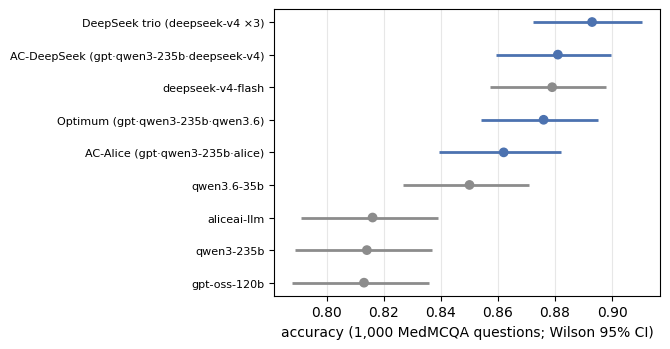

In [7]:
a = acc.sort_values('accuracy')
fig, ax = plt.subplots(figsize=(6.8, 3.6))
y = np.arange(len(a))
col = ['#4C72B0' if k == 'panel' else '#8C8C8C' for k in a.kind]
ax.hlines(y, a.ci_lo, a.ci_hi, color=col, lw=2)
ax.scatter(a.accuracy, y, color=col, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(a.system, fontsize=8)
ax.set_xlabel('accuracy (1,000 MedMCQA questions; Wilson 95% CI)')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(P.path_join(P.FIGURES, 'S_NB08_medmcqa.png'), dpi=220)
